# Advanced walkthrough II: a nonlinear 3D inverse problem with heavy-tailed noise

**Hydraulic tomography.** Water is pumped into an aquifer block at one well at a time, and the hydraulic head (water
pressure) is measured at sensors in nine wells. From these measurements we infer the **log-conductivity** $m(x)$ of
the block, i.e. where the rock lets water through easily and where it does not.

Compared with the [Stokes walkthrough](stokes_inverse.ipynb), everything that made that problem easy is gone:

* **3D**: the unknown is a field in a three-dimensional block;
* **nonlinear forward model**: the head depends on the conductivity $e^{m}$ nonlinearly, so the posterior is not
  Gaussian and has no closed form;
* **non-Gaussian noise**: the measurement errors are Student-$t$ (heavy tails: occasional large errors, "outliers");
* **low rank**: only a few dozen directions in parameter space are informed by the data.

The strategy, and what `ngsrng` contributes:

1. the **MAP point** by Gauss–Newton: every step is an exact Gaussian conditioning (`prior.condition`), and the
   heavy-tailed noise is handled by re-weighting the observations (`posterior(noise_scaling=...)`, an $l\times l$
   eigendecomposition per re-weighting);
2. the **Laplace approximation** at the MAP point: a Gaussian with an exact variance map and a low-rank structure;
3. **MCMC** to check it: function-space samplers that only need samples from `ngsrng` Gaussians and forward solves,
   including a Gibbs sampler for the heavy-tailed noise whose Gaussian step is again a re-weighted posterior.

Sections:

1. [The problem](#1.-The-problem)
2. [Mesh, wells and sensors](#2.-Mesh,-wells-and-sensors)
3. [The prior in 3D](#3.-The-prior-in-3D)
4. [Forward model and its derivative](#4.-Forward-model-and-its-derivative)
5. [Synthetic data with heavy-tailed noise](#5.-Synthetic-data-with-heavy-tailed-noise)
6. [The MAP point: Gauss–Newton with re-weighting](#6.-The-MAP-point:-Gauss–Newton-with-re-weighting)
7. [The Laplace approximation](#7.-The-Laplace-approximation)
8. [Checking the Laplace approximation with MCMC](#8.-Checking-the-Laplace-approximation-with-MCMC)
9. [Summary](#9.-Summary)

The notebook runs in about four minutes; most of it is the MCMC in section 8.

## 0. Setup

3D fields are shown with NGSolve's `Draw` on a vertical clipping plane through the middle row of wells (drag to
rotate, move the plane in the panel). matplotlib is used only for data, traces and spectra.

In [1]:
import ngsrng  # noqa: I001  (first: it imports torch before NGSolve, ngsrng known issue 1)
import time

import matplotlib.pyplot as plt
import ngsolve as ngs
import numpy as np
import torch
from netgen.occ import Box, OCCGeometry, Pnt, X, Y
from ngsolve.webgui import Draw

from ngsrng.space import to_scipy

%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 85}}

look = {"settings": {"Objects": {"Wireframe": False}, "Colormap": {"ncolors": 32}}}
cut = {"vec": (0, -1, 0), "pnt": (0.5, 0.5, 0.25)}           # vertical plane y = 0.5 through three wells


def draw3d(field, mesh, **kw):
    # a 3D field on the clipping plane (order=1: first-order fields are drawn exactly with linear patches)
    return Draw(field, mesh, clipping=cut, order=1, **look, **kw)


def as_gf(coefficients, space):
    gf = ngs.GridFunction(space)
    gf.vec.FV().NumPy()[:] = np.asarray(coefficients, dtype=float)
    return gf


def t(x):
    return torch.from_numpy(np.ascontiguousarray(x))

**Problem parameters.** Change them and re-run. `sigma_m` is the prior standard deviation of the log-conductivity:
0.3 means conductivities varying by factors of about $e^{\pm0.6}\approx 1.8$; larger values make the problem more
nonlinear and the MCMC check much slower (see section 8). `maxh` sets the mesh size (smaller is finer and slower).

In [2]:
maxh = 0.07              # mesh size
length, nu = 0.3, 1.5    # prior correlation length and smoothness (Matern)
sigma_m = 0.3            # prior standard deviation of the log-conductivity
noise_level = 0.01       # noise scale: noise_level x largest observed head
nu_noise = 3.0           # Student-t degrees of freedom of the noise (smaller: heavier tails)
mcmc_steps = 1500        # length of each MCMC chain in section 8
seed = 1

## 1. The problem

In the block $D = (0,1)\times(0,1)\times(0,\tfrac12)$, pumping test $k$ injects water through well $k$ (a source $f_k$
along the well) and the hydraulic head $u_k$ solves

$$
-\nabla\cdot\big(e^{m}\,\nabla u_k\big) = f_k \quad\text{in } D, \qquad u_k = 0 \text{ on the four sides}, \qquad
e^{m}\,\partial_n u_k = 0 \text{ on top and bottom}.
$$

The data are the heads at the sensors $x_1,\dots,x_s$ in all tests, $d = \mathcal F(m) + e$, with independent
Student-$t$ errors $e_j = \sigma\,\tau_j$, $\tau_j\sim t_\nu$. With a Gaussian prior $\mu_0 = \mathcal N(0, \mathcal C)$
the posterior is

$$
\pi(m \mid d) \propto \exp\big(-\Phi(m)\big)\,\mu_0(dm), \qquad
\Phi(m) = \sum_j \frac{\nu+1}{2}\log\Big(1 + \frac{r_j(m)^2}{\nu}\Big), \quad r_j(m) = \frac{d_j - \mathcal F_j(m)}{\sigma}.
$$

$\mathcal F$ is nonlinear and $\Phi$ is not quadratic, so the posterior is neither Gaussian nor available in closed
form.

## 2. Mesh, wells and sensors

Nine vertical wells on a $3\times3$ grid, each with sensors at three depths (27 sensors). Four pumping tests, one at
each corner well. The parameter $m$ and the heads use first-order elements on the same mesh.

In [3]:
block = Box(Pnt(0, 0, 0), Pnt(1, 1, 0.5))
block.faces.Min(X).name = "west"
block.faces.Max(X).name = "east"
block.faces.Min(Y).name = "south"
block.faces.Max(Y).name = "north"
mesh = ngs.Mesh(OCCGeometry(block).GenerateMesh(maxh=maxh))
Vm = ngs.H1(mesh, order=1)                                           # log-conductivity
Vu = ngs.H1(mesh, order=1, dirichlet="west|east|south|north")        # heads

grid = [0.25, 0.5, 0.75]
wells = [(x, y) for x in grid for y in grid]
sensors = np.array([(x, y, z) for x, y in wells for z in (0.1, 0.25, 0.4)])
pumping = [(0.25, 0.25), (0.75, 0.25), (0.25, 0.75), (0.75, 0.75)]
width = 0.05                                                         # width of the well source
sources = [ngs.exp(-((ngs.x - x0) ** 2 + (ngs.y - y0) ** 2) / (2 * width**2)) / (2 * np.pi * width**2)
           for x0, y0 in pumping]
print(f"{mesh.ne} tetrahedra; {Vm.ndof} parameter unknowns; {len(sensors)} sensors x {len(pumping)} tests "
      f"= {len(sensors) * len(pumping)} observations")
draw3d(sum(sources), mesh);

8863 tetrahedra; 1993 parameter unknowns; 27 sensors x 4 tests = 108 observations


<netgen.webgui.WebGuiWidget>: Run `pip install anywidget` to enable WebGuiWidget in Jupyter

## 3. The prior in 3D

A Matérn prior with smoothness $\nu = 1.5$: in 3D that is $\mathcal C = s^2(\kappa^2-\Delta)^{-3}$, an odd power,
which `ngsrng` samples exactly with stiffness-shaped noise and two solves per sample. As in the Stokes walkthrough, a
Robin boundary condition removes the boundary variance inflation. The constant $\beta = \kappa/1.42$ was tuned for
$\nu = 1$ in 2D, so we check it in 3D: the largest deviation of the exact variance from its interior value, at points
on faces, edges and a corner, for a range of factors $c$ in $\beta = c\,\kappa$ (`beta=None` would let ngsrng estimate $\beta$ for the space,
see `ngsrng.tune_robin`):

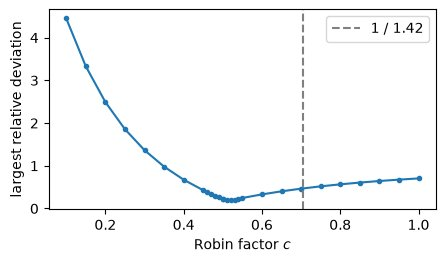

best factor 0.52 (largest deviation 18.9%)


In [4]:
probe = ([(x, 0.0, 0.25) for x in np.linspace(0, 0.5, 6)] + [(0.0, 0.0, z) for z in np.linspace(0, 0.25, 4)]
         + [(x, 0.5, 0.0) for x in np.linspace(0, 0.5, 6)] + [(0.5, 0.5, z) for z in (0.0, 0.05, 0.1)])
centre = (0.5, 0.5, 0.25)
kappa = np.sqrt(8 * nu) / length


def largest_deviation(c):
    g = ngsrng.default_rng(Vm, correlation=ngsrng.matern_correlation(length, nu, boundary="robin", beta=c * kappa),
                           dtype="float64").gaussian()
    v = np.diag(ngsrng.functional_covariance(g, points=probe + [centre]))
    return np.abs(v[:-1] / v[-1] - 1).max()


factors = np.linspace(0.1, 1.0, 19)                                  # coarse scan, then a finer one around the best
deviation = [largest_deviation(c) for c in factors]
coarse = factors[int(np.argmin(deviation))]
fine = np.linspace(coarse - 0.04, coarse + 0.04, 9)
factors = np.concatenate([factors, fine])
deviation += [largest_deviation(c) for c in fine]
order = np.argsort(factors)
factors, deviation = factors[order], np.array(deviation)[order]
best = factors[int(np.argmin(deviation))]
fig, ax = plt.subplots(figsize=(5, 2.6))
ax.plot(factors, deviation, ".-")
ax.axvline(1 / 1.42, color="gray", ls="--", label="1 / 1.42")
ax.set_xlabel(r"Robin factor $c$"), ax.set_ylabel("largest relative deviation"), ax.legend()
plt.show()
print(f"best factor {best:.2f} (largest deviation {min(deviation):.1%})")

In 3D with $\nu = 1.5$ the best constant is far from the 2D value: tuning matters. The remaining deviation sits
where faces meet (edges and, most of all, corners), which no constant $\beta$ can fix. The prior with the tuned
factor, scaled to standard deviation `sigma_m`, its exact variance at random points (computed, not sampled), and one
sample:

In [5]:
spec = ngsrng.matern_correlation(length, nu, boundary="robin", beta=best * kappa).bind(Vm)
spec.scale *= sigma_m                                                 # unit variance -> sigma_m^2
prior = ngsrng.Gaussian(Vm, spec, dtype="float64", seed=seed)
print(prior.plan["structure"])
t0 = time.time()
local = ngsrng.local_covariance(prior)                               # exact: the variance at any point
anywhere = np.random.default_rng(0).uniform([0, 0, 0], [1, 1, 0.5], (2000, 3))
v = local.values(ngsrng.observation_operator(Vm, points=anywhere)) / sigma_m**2
print(f"exact prior variance ({local.method}, {time.time() - t0:.0f} s): between {v.min():.2f} and {v.max():.2f} "
      f"times sigma_m^2 at 2000 random points")
draw3d(prior.sample(), mesh);

C = A^-3: stiffness-shaped noise + 2 solve(s) per sample


exact prior variance (exact (all columns), 8 s): between 0.66 and 1.18 times sigma_m^2 at 2000 random points


<netgen.webgui.WebGuiWidget>: Run `pip install anywidget` to enable WebGuiWidget in Jupyter

## 4. Forward model and its derivative

For a given $m$: assemble $A(m) = \int e^{m}\nabla u\cdot\nabla v\,dx$, factorise once, and solve one system per
pumping test. The derivative (Jacobian) of the observations follows from the adjoint method: differentiating
$A(m)u_k = f_k$ gives $A(m)\,\delta u_k = -B_k\,\delta m$ with $B_k$ the matrix of
$\int e^{m}\,\delta m\,\nabla u_k\cdot\nabla v\,dx$, so

$$
J_k = -\,O A(m)^{-1} B_k, \qquad J_k^\top = -B_k^\top A(m)^{-1} O^\top .
$$

$A(m)^{-1}O^\top$ is one adjoint solve per sensor (shared by all tests, since $A$ is symmetric), and $B_k$ is one
assembly per test.

In [6]:
u_, v_ = Vu.TnT()
loads = [ngs.LinearForm(f * v_ * ngs.dx).Assemble() for f in sources]
O = ngsrng.observation_operator(Vu, points=sensors)                 # (sensors x head dofs)
n_obs = len(sensors) * len(pumping)


def solve(m_coefficients):
    # heads of all tests for a log-conductivity (coefficients): states, the factorisation and m as a GridFunction
    m = as_gf(m_coefficients, Vm)
    A = ngs.BilinearForm(ngs.exp(m) * ngs.grad(u_) * ngs.grad(v_) * ngs.dx).Assemble()
    A_inv = A.mat.Inverse(Vu.FreeDofs(), "sparsecholesky")
    heads = []
    for load in loads:
        u = ngs.GridFunction(Vu)
        u.vec.data = A_inv * load.vec
        heads.append(u)
    return heads, A_inv, m


def forward(m_coefficients):
    heads, _, _ = solve(m_coefficients)
    return np.concatenate([O @ u.vec.FV().NumPy() for u in heads])


def jacobian(m_coefficients):
    # observations and the Jacobian (n_obs x parameter dofs) at m
    heads, A_inv, m = solve(m_coefficients)
    adjoint = np.empty((Vu.ndof, len(sensors)))
    rhs, sol = heads[0].vec.CreateVector(), heads[0].vec.CreateVector()
    for j in range(len(sensors)):
        rhs.FV().NumPy()[:] = O[j].toarray()[0]
        sol.data = A_inv * rhs
        adjoint[:, j] = sol.FV().NumPy()
    rows = []
    for u in heads:
        Bk = ngs.BilinearForm(trialspace=Vm, testspace=Vu)
        Bk += ngs.exp(m) * Vm.TrialFunction() * ngs.grad(u) * ngs.grad(v_) * ngs.dx
        rows.append(-(to_scipy(Bk.Assemble().mat).T @ adjoint).T)
    return np.concatenate([O @ u.vec.FV().NumPy() for u in heads]), np.vstack(rows)

The "true" log-conductivity is a draw from the prior, so that the Bayesian checks below are meaningful. Its first
pumping test, and a finite-difference check of the Jacobian:

In [7]:
m_true = prior.sample(1).double().numpy()[:, 0]
t0 = time.time()
d_clean, J_true = jacobian(m_true)
print(f"forward model {len(pumping)} tests + Jacobian: {time.time() - t0:.2f} s")
direction = prior.sample(1).double().numpy()[:, 0]
eps = 1e-6
fd = (forward(m_true + eps * direction) - forward(m_true - eps * direction)) / (2 * eps)
gap = np.abs(J_true @ direction - fd).max() / np.abs(fd).max()
print(f"Jacobian vs finite differences: relative difference {gap:.1e}")
draw3d(as_gf(m_true, Vm), mesh);

forward model 4 tests + Jacobian: 0.23 s
Jacobian vs finite differences: relative difference 2.2e-09


<netgen.webgui.WebGuiWidget>: Run `pip install anywidget` to enable WebGuiWidget in Jupyter

In [8]:
heads_true, _, _ = solve(m_true)
draw3d(heads_true[0], mesh);

<netgen.webgui.WebGuiWidget>: Run `pip install anywidget` to enable WebGuiWidget in Jupyter

## 5. Synthetic data with heavy-tailed noise

Student-$t$ noise with `nu_noise` degrees of freedom and scale $\sigma$ = `noise_level` times the largest head. Most
errors are of size $\sigma$, but some are much larger:

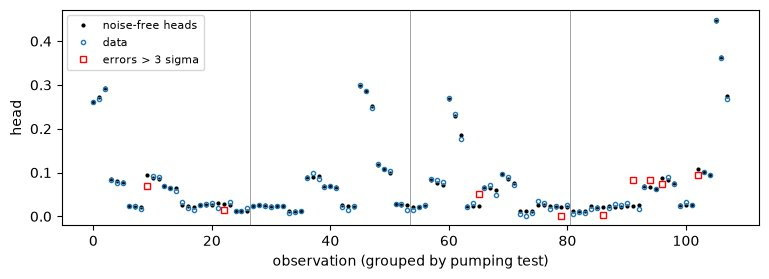

sigma = 4.47e-03; 9 of 108 errors exceed 3 sigma (a Gaussian would give about 0.3)


In [9]:
sigma = noise_level * np.abs(d_clean).max()
errors = sigma * np.random.default_rng(seed + 1).standard_t(nu_noise, n_obs)
data = d_clean + errors
outliers = np.abs(errors) > 3 * sigma
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.plot(d_clean, "k.", ms=4, label="noise-free heads")
ax.plot(np.flatnonzero(~outliers), data[~outliers], "o", ms=3, mfc="none", label="data")
ax.plot(np.flatnonzero(outliers), data[outliers], "rs", ms=5, mfc="none", label="errors > 3 sigma")
for k in range(1, len(pumping)):
    ax.axvline(k * len(sensors) - 0.5, color="gray", lw=0.5)
ax.set_xlabel("observation (grouped by pumping test)"), ax.set_ylabel("head"), ax.legend(fontsize=8)
plt.show()
print(f"sigma = {sigma:.2e}; {outliers.sum()} of {n_obs} errors exceed 3 sigma "
      f"(a Gaussian would give about {0.0027 * n_obs:.1f})")

## 6. The MAP point: Gauss–Newton with re-weighting

The MAP point minimises $\Phi(m) + \tfrac12\|m\|^2_{\mathcal C^{-1}}$. Gauss–Newton replaces $\mathcal F$ by its
linearisation $\mathcal F(m_k) + J(m - m_k)$, and Student-$t$ noise is a Gaussian with an unknown variance per
observation, $\sigma^2/w_j$. For fixed weights the step is therefore a **linear Gaussian inverse problem**, and its
solution is the posterior mean of `prior.condition` with the linearised data $\tilde d = d - \mathcal F(m_k) + Jm_k$.
The weights are updated from the residuals, $w_j = (\nu+1)/(\nu + r_j^2)$, which down-weights outliers (iteratively
reweighted least squares, the EM algorithm for the $t$ model). Re-weighting does not change the factorisation, so
`posterior(noise_scaling=w)` costs only an $l\times l$ eigendecomposition.

The same loop with all weights equal to one is Gauss–Newton for a Gaussian likelihood, for comparison.

In [10]:
def objective(m, d=None, robust=True):
    d = forward(m) if d is None else d
    r = (data - d) / sigma
    misfit = 0.5 * (nu_noise + 1) * np.sum(np.log1p(r**2 / nu_noise)) if robust else 0.5 * np.sum(r**2)
    return misfit + 0.5 * m @ prior.apply_precision(t(m)).numpy()


def gauss_newton(robust=True, iterations=12, inner=3, tol=1e-3):
    m = prior.mean.copy()
    for it in range(iterations):
        t0 = time.time()
        d, J = jacobian(m)
        f0 = objective(m, d, robust)
        obs = ngsrng.LinearObservations(prior, J, noise=sigma**2)     # factorised once per linearisation
        d_lin = data - d + J @ m
        m_new = m
        for _ in range(inner if robust else 1):                       # IRLS: cheap re-weighted conditionings
            r = (d_lin - J @ m_new) / sigma
            w = (nu_noise + 1) / (nu_noise + r**2) if robust else np.ones(n_obs)
            m_new = obs.posterior(data=d_lin, noise_scaling=w).mean
        step, alpha = m_new - m, 1.0
        while objective(m + alpha * step, robust=robust) > f0 and alpha > 1e-3:   # backtracking
            alpha /= 2
        m = m + alpha * step
        change = alpha * np.linalg.norm(step) / max(np.linalg.norm(m), 1e-300)
        print(f"  iteration {it + 1}: objective {objective(m, robust=robust):9.2f}, step {alpha:.2f}, "
              f"relative change {change:.1e} ({time.time() - t0:.1f} s)")
        if change < tol:
            break
    return m


mass = ngsrng.SpaceInfo(Vm).mass


def error(m):
    return np.sqrt((m - m_true) @ mass @ (m - m_true) / (m_true @ mass @ m_true))


print("Student-t likelihood:")
m_map = gauss_newton(robust=True)
print("Gaussian likelihood:")
m_gauss = gauss_newton(robust=False)
print(f"relative L2 error of the MAP point: Student-t {error(m_map):.2f}, Gaussian {error(m_gauss):.2f}")

Student-t likelihood:


  iteration 1: objective    116.68, step 1.00, relative change 1.0e+00 (1.7 s)


  iteration 2: objective    104.60, step 1.00, relative change 1.7e-01 (1.4 s)


  iteration 3: objective    104.41, step 1.00, relative change 1.6e-02 (1.7 s)


  iteration 4: objective    104.41, step 1.00, relative change 1.5e-03 (1.4 s)


  iteration 5: objective    104.41, step 1.00, relative change 1.7e-04 (1.1 s)
Gaussian likelihood:


  iteration 1: objective    446.12, step 1.00, relative change 1.0e+00 (1.4 s)


  iteration 2: objective    217.91, step 1.00, relative change 2.5e-01 (1.3 s)


  iteration 3: objective    215.69, step 1.00, relative change 3.3e-02 (1.4 s)


  iteration 4: objective    215.69, step 1.00, relative change 1.5e-03 (1.6 s)


  iteration 5: objective    215.69, step 1.00, relative change 2.2e-04 (1.8 s)
relative L2 error of the MAP point: Student-t 0.60, Gaussian 0.64


Normalised residuals at the two MAP points. The Gaussian likelihood pulls the field towards the outliers (their
residuals shrink, and the error of the field grows); the Student-$t$ likelihood leaves them large. The difference is
visible at the largest errors:

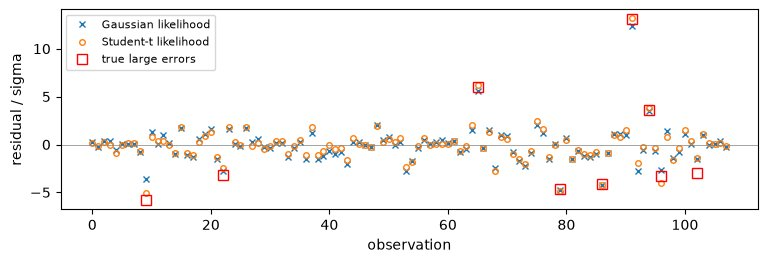

<netgen.webgui.WebGuiWidget>: Run `pip install anywidget` to enable WebGuiWidget in Jupyter

In [11]:
fig, ax = plt.subplots(figsize=(9, 2.6))
for m, label, marker in ((m_gauss, "Gaussian likelihood", "x"), (m_map, "Student-t likelihood", "o")):
    ax.plot((data - forward(m)) / sigma, marker, ms=4, mfc="none", label=label)
ax.plot(np.flatnonzero(outliers), errors[outliers] / sigma, "rs", ms=7, mfc="none", label="true large errors")
ax.axhline(0, color="gray", lw=0.5)
ax.set_xlabel("observation"), ax.set_ylabel("residual / sigma"), ax.legend(fontsize=8)
plt.show()
draw3d(as_gf(m_map, Vm), mesh);

## 7. The Laplace approximation

The Laplace approximation is the Gaussian centred at the MAP point whose precision is the Hessian of the negative log
posterior there, with the Gauss–Newton approximation $J^\top H_\Phi J$ for the misfit part. For Student-$t$ noise the
misfit curvature per observation is $\rho''(r_j) = (\nu+1)(\nu - r_j^2)/(\nu + r_j^2)^2$; it is negative for
large residuals (an outlier carries no information about the curvature), so it is clipped at zero. That is again a
re-weighted linear Gaussian problem: `posterior(noise_scaling=...)` with these weights, at the linearisation at the
MAP point, and `mean=` centres it at the MAP point.

In [12]:
d_map, J = jacobian(m_map)
r_map = (data - d_map) / sigma
curvature = np.clip((nu_noise + 1) * (nu_noise - r_map**2) / (nu_noise + r_map**2) ** 2, 0, None)
obs_map = ngsrng.LinearObservations(prior, J, noise=sigma**2)
laplace = obs_map.posterior(mean=m_map, noise_scaling=curvature, seed=seed)
print(f"{(curvature == 0).sum()} of {n_obs} observations carry no curvature (residual > sqrt(nu) sigma)")
t0 = time.time()
var_laplace = ngsrng.pointwise_variance(laplace)
print(f"exact Laplace variance map in {time.time() - t0:.1f} s ({ngsrng.local_covariance(laplace).method})")
draw3d(ngs.sqrt(ngs.IfPos(var_laplace, var_laplace, 0)), mesh);

20 of 108 observations carry no curvature (residual > sqrt(nu) sigma)


exact Laplace variance map in 5.7 s (prior (exact (all columns)) + exact rank-88 update)


<netgen.webgui.WebGuiWidget>: Run `pip install anywidget` to enable WebGuiWidget in Jupyter

The posterior standard deviation is smallest around the sensors and grows away from the wells, towards the sides of
the block. **Low rank:** the eigenvalues of the prior-preconditioned (weighted) data-misfit Hessian show how many
directions the data inform (observations with zero curvature weight contribute zero eigenvalues, drawn at
$10^{-8}$), and a randomised low-rank update with about that many directions reproduces the variance map:

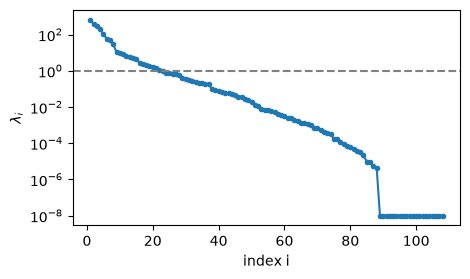

22 of 108 directions are informed by the data (lambda > 1)


rank  11: relative error of the Laplace variance map 3.0e-01


rank  22: relative error of the Laplace variance map 1.1e-01


rank  42: relative error of the Laplace variance map 6.7e-03


In [13]:
lam = np.sort(np.linalg.eigvalsh((obs_map.r * curvature) @ obs_map.r.T))[::-1]   # eigenvalues of F^T W F
informed = int((lam > 1).sum())
fig, ax = plt.subplots(figsize=(5, 2.8))
ax.semilogy(np.arange(1, lam.size + 1), np.clip(lam, 1e-8, None), ".-")
ax.axhline(1, color="gray", ls="--")
ax.set_xlabel("index i"), ax.set_ylabel(r"$\lambda_i$")
plt.show()
print(f"{informed} of {n_obs} directions are informed by the data (lambda > 1)")
for rank in (informed // 2, informed, informed + 20):
    approx = ngsrng.LinearObservations(prior, J, noise=sigma**2, rank=rank).posterior(noise_scaling=curvature)
    v = ngsrng.pointwise_variance(approx)
    gap = np.sqrt(ngs.Integrate((v - var_laplace) ** 2, mesh) / ngs.Integrate(var_laplace**2, mesh))
    print(f"rank {rank:3d}: relative error of the Laplace variance map {gap:.1e}")

## 8. Checking the Laplace approximation with MCMC

The Laplace approximation is only as good as the linearisation (and the quadratic approximation of the noise model)
over the region the posterior occupies. MCMC samples the true posterior. In function space, the standard choice is the
preconditioned Crank–Nicolson (pCN) sampler (Cotter, Roberts, Stuart & White 2013): propose

$$
m' = \sqrt{1-\beta^2}\, m + \beta\,\xi, \qquad \xi \sim \mu_0,
$$

and accept with probability $\min(1, e^{\Phi(m) - \Phi(m')})$. It is well defined in function space, so its
acceptance rate does not degrade under mesh refinement, but its proposals ignore the data. The generalised pCN
(gpCN, Rudolf & Sprungk 2018) draws $\xi$ from the **Laplace approximation** $\mathcal N(m_L, \mathcal C_L)$ instead,

$$
m' = m_L + \sqrt{1-\beta^2}\,(m - m_L) + \beta\,\xi, \qquad \xi \sim \mathcal N(0, \mathcal C_L),
$$

and accepts with $\Psi(m) = \Phi(m) + \langle m - m_0, m_L - m_0\rangle_{\mathcal C^{-1}}
- \tfrac12\|W^{1/2}J(m - m_L)\|^2/\sigma^2$ in place of $\Phi$ (the log density of the posterior with respect to the
Laplace approximation, up to a constant). Both need only Gaussian samples, which `ngsrng` provides.

In [14]:
m_L = laplace.mean
d_lin_map = data - d_map + J @ m_map                                  # linearised data at the MAP point


def misfit(d, w=None):
    # Student-t misfit, or with noise precisions w the Gaussian misfit of the scale-mixture model
    r = (data - d) / sigma
    return 0.5 * (nu_noise + 1) * np.sum(np.log1p(r**2 / nu_noise)) if w is None else 0.5 * np.sum(w * r**2)


def log_ratio(gauss, weights):
    # Psi(m, d): log density of the target with respect to the Gaussian `gauss` (a Laplace approximation)
    centre = gauss.mean
    shift = prior.apply_precision(t(centre - prior.mean)).numpy()      # C^-1 (m_L - m_0), a dual vector
    return lambda m, d, w=None: (misfit(d, w) + (m - prior.mean) @ shift
                                 - 0.5 * np.sum(weights * ((J @ (m - centre)) / sigma) ** 2))


def iact(x):
    # integrated autocorrelation time (Sokal's adaptive window)
    x = np.asarray(x) - np.mean(x)
    f = np.fft.rfft(x, 2 * len(x))
    ac = np.fft.irfft(f * np.conj(f))[: len(x)]
    ac /= ac[0]
    tau = 1.0
    for k in range(1, len(x)):
        tau += 2 * ac[k]
        if k >= 5 * tau:
            break
    return tau


test_points = np.random.default_rng(3).uniform([0.05, 0.05, 0.05], [0.95, 0.95, 0.45], (60, 3))
E = ngsrng.observation_operator(Vm, points=test_points)
volume = mass @ np.ones(Vm.ndof) / ngs.Integrate(1, mesh)            # m -> its average over the block


def summary(name, states, rate, seconds):
    qoi = np.column_stack([states @ E[:5].T.toarray(), states @ volume])   # 5 point values, block average
    tau = max(iact(qoi[:, j]) for j in range(qoi.shape[1]))
    print(f"{name:6s}: {len(states)} steps in {seconds:3.0f} s, acceptance {rate:4.0%}, "
          f"autocorrelation time ~{tau:4.0f} steps, effective sample size ~{len(states) / tau:4.0f}")
    return tau

In [15]:
def pcn_family(kind, steps, beta, chunk=200):
    # pCN (prior proposals) or gpCN (Laplace proposals) for the Student-t posterior
    gauss, energy = (prior, lambda m, d: misfit(d)) if kind == "pCN" else (laplace, log_ratio(laplace, curvature))
    centre = gauss.mean
    rng = np.random.default_rng(seed + 2)
    m = m_L.copy()                                                    # start at the MAP point
    d = forward(m)
    e = energy(m, d)
    states, accepted = np.empty((steps, Vm.ndof)), 0
    for k in range(steps):
        if k % chunk == 0:
            xi = gauss.sample(chunk).double().numpy() - centre[:, None]  # Gaussian samples in batches
        proposal = centre + np.sqrt(1 - beta**2) * (m - centre) + beta * xi[:, k % chunk]
        d_prop = forward(proposal)
        e_prop = energy(proposal, d_prop)
        if np.log(rng.uniform()) < e - e_prop:
            m, d, e = proposal, d_prop, e_prop
            accepted += 1
        states[k] = m
    return states, accepted / steps


runs = {}
for kind, steps, beta in (("pCN", mcmc_steps, 0.05), ("gpCN", mcmc_steps, 0.5)):
    t0 = time.time()
    states, rate = pcn_family(kind, steps, beta)
    runs[kind] = (states, rate, summary(kind, states, rate, time.time() - t0))

pCN   : 1500 steps in  78 s, acceptance  43%, autocorrelation time ~ 221 steps, effective sample size ~   7


gpCN  : 1500 steps in  62 s, acceptance  40%, autocorrelation time ~  63 steps, effective sample size ~  24


pCN's proposals ignore the 108 data, so only tiny steps ($\beta = 0.05$) are accepted often enough, and the chain
crawls. gpCN's proposals follow the Laplace approximation, so its efficiency depends on how well one Gaussian matches
the posterior. Two things limit that: the nonlinearity of the PDE, and the noise model, since the Student-$t$ misfit
is far from quadratic.

**Gibbs sampling for heavy-tailed noise.** A different route uses the structure of the noise model. Student-$t$ noise
is a Gaussian with a random precision per observation:
$e_j \mid \tau_j \sim \mathcal N(0, \sigma^2/\tau_j)$, $\tau_j \sim \Gamma(\tfrac\nu2, \tfrac\nu2)$. Sampling
$(m, \tau)$ jointly by alternating two steps gives the same posterior for $m$:

1. $\tau \mid m$: independent Gamma draws, $\tau_j \sim \Gamma\big(\tfrac{\nu+1}2, \tfrac{\nu + r_j^2}2\big)$ (exact);
2. $m \mid \tau$: a posterior with *Gaussian* noise of variances $\sigma^2/\tau_j$, sampled by one gpCN step whose
   Laplace approximation uses the current $\tau$: `obs_map.posterior(noise_scaling=tau)`, an $l\times l$
   eigendecomposition. The rest of the factorisation is shared, so a re-weighted posterior and one sample from it
   take about 15 ms here.

Each step now sees a Gaussian likelihood, but the proposal changes with $\tau$ and the chain must also explore $\tau$;
which sampler is more efficient depends on the problem.

In [16]:
def gibbs(steps, beta):
    rng = np.random.default_rng(seed + 3)
    m = m_L.copy()
    d = forward(m)
    states, accepted, t_gauss = np.empty((steps, Vm.ndof)), 0, 0.0
    for k in range(steps):
        r = (data - d) / sigma
        tau = rng.gamma((nu_noise + 1) / 2, 2 / (nu_noise + r**2))     # step 1: noise precisions given m
        t0 = time.time()
        reference = obs_map.posterior(data=d_lin_map, noise_scaling=tau, seed=int(rng.integers(2**31)))
        centre = reference.mean
        xi = reference.sample(1).double().numpy()[:, 0] - centre
        t_gauss += time.time() - t0
        energy = log_ratio(reference, tau)                              # step 2: gpCN for m given tau
        proposal = centre + np.sqrt(1 - beta**2) * (m - centre) + beta * xi
        d_prop = forward(proposal)
        if np.log(rng.uniform()) < energy(m, d, tau) - energy(proposal, d_prop, tau):
            m, d = proposal, d_prop
            accepted += 1
        states[k] = m
    print(f"re-weighted Laplace approximations and samples: {1000 * t_gauss / steps:.0f} ms per sweep")
    return states, accepted / steps


t0 = time.time()
states, rate = gibbs(mcmc_steps, 0.6)
runs["Gibbs"] = (states, rate, summary("Gibbs", states, rate, time.time() - t0))

re-weighted Laplace approximations and samples: 7 ms per sweep
Gibbs : 1500 steps in  72 s, acceptance  44%, autocorrelation time ~  50 steps, effective sample size ~  30


All three chains have the same length; compare their effective sample sizes above. Traces of the average
log-conductivity over the block (the first 400 steps of each chain):

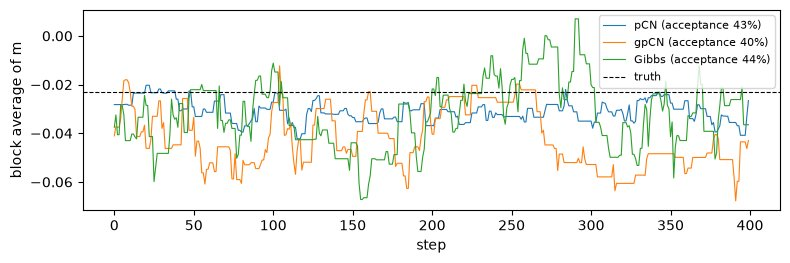

In [17]:
fig, ax = plt.subplots(figsize=(9, 2.6))
for kind, (states, rate, tau) in runs.items():
    ax.plot((states @ volume)[:400], lw=0.8, label=f"{kind} (acceptance {rate:.0%})")
ax.axhline(m_true @ volume, color="k", ls="--", lw=0.8, label="truth")
ax.set_xlabel("step"), ax.set_ylabel("block average of m"), ax.legend(fontsize=8)
plt.show()

**Laplace vs MCMC.** Posterior means and standard deviations at 60 random points, from the MCMC chain with the larger
effective sample size (gpCN or Gibbs; error bars: two Monte Carlo standard errors) and from the Laplace approximation
(exact, via `functional_covariance`):

using the Gibbs chain


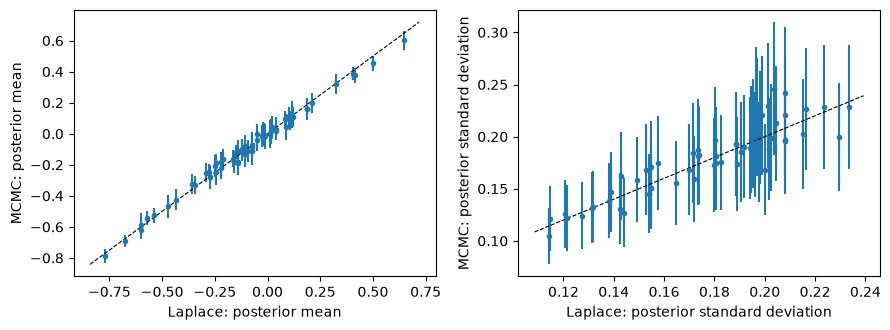

median |MCMC mean - Laplace mean| / posterior sd: 0.12; median sd ratio Laplace / MCMC: 0.99 (Monte Carlo error of the MCMC sd: ~13%)


In [18]:
best_chain = max(("gpCN", "Gibbs"), key=lambda k: len(runs[k][0]) / runs[k][2])
states, rate, tau = runs[best_chain]
print(f"using the {best_chain} chain")
values = states @ E.T.toarray()                                       # (steps x points)
ess = len(states) / tau
mc_mean, mc_sd = values.mean(0), values.std(0)
lap_mean = E @ m_L
lap_sd = np.sqrt(np.diag(ngsrng.functional_covariance(laplace, points=test_points)))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].errorbar(lap_mean, mc_mean, yerr=2 * mc_sd / np.sqrt(ess), fmt="o", ms=3)
axes[1].errorbar(lap_sd, mc_sd, yerr=2 * mc_sd / np.sqrt(2 * ess), fmt="o", ms=3)
for ax, name in zip(axes, ("posterior mean", "posterior standard deviation")):
    lo, hi = ax.get_xlim()
    ax.plot([lo, hi], [lo, hi], "k--", lw=0.8)
    ax.set_xlabel(f"Laplace: {name}"), ax.set_ylabel(f"MCMC: {name}")
plt.tight_layout()
plt.show()
print(f"median |MCMC mean - Laplace mean| / posterior sd: {np.median(np.abs(mc_mean - lap_mean) / mc_sd):.2f}; "
      f"median sd ratio Laplace / MCMC: {np.median(lap_sd / mc_sd):.2f} (Monte Carlo error of the MCMC sd: "
      f"~{1 / np.sqrt(2 * ess):.0%})")

The MCMC posterior mean as an FE function (the average of the chain's states), to compare with the MAP point above:

In [19]:
draw3d(as_gf(states.mean(0), Vm), mesh);

<netgen.webgui.WebGuiWidget>: Run `pip install anywidget` to enable WebGuiWidget in Jupyter

**How far does this go?** MCMC with Gaussian proposals needs the Laplace approximation to be roughly right
*everywhere the posterior has mass*. Measured while preparing this notebook (same mesh, data model and samplers, with
the Robin factor 1/1.42 and the prior's earlier boundary noise, which lacked the Robin term (fixed 2026-11-09):
the trend carries over, the exact numbers would change; 3000 steps, MAP-centred Laplace approximation):

| `sigma_m` | sampler | acceptance | autocorrelation times |
|---|---|---|---|
| 0.5 | gpCN ($\beta=0.5$) | 14% | ~45–140 steps |
| 0.5 | Gibbs + gpCN ($\beta=0.6$) | 10% | ~60–150 steps |
| 1.0 | gpCN ($\beta=0.3$) | 15% | ~95–155 steps |
| 1.0 | Gibbs + gpCN ($\beta=0.4$) | 4% | ~120–370 steps |

With larger `sigma_m` the linearisation breaks down across the posterior (small-scale fluctuations change the
effective conductivity, and with it every head), so reliable checks need far longer chains or samplers that use
gradients ($\infty$-MALA; DILI, Cui, Law & Marzouk 2016). Centring matters: the same gpCN with the Laplace
approximation centred away from the MAP point had autocorrelation times of 300–900 steps at `sigma_m = 0.5`.

## 9. Summary

* A nonlinear inverse problem reduces to a **sequence of linear Gaussian ones**: every Gauss–Newton step and the
  Laplace approximation are exact conditionings of the prior on a linearised observation operator, built from one
  adjoint solve per sensor.
* **Heavy-tailed noise** fits the same machinery through re-weighting (`posterior(noise_scaling=w)`), which costs an
  $l\times l$ eigendecomposition per re-weighting; the robust MAP point ignores outliers that pull the Gaussian one
  away.
* In **3D**, the Laplace approximation still comes with an **exact variance map** (prior variance plus an exact
  low-rank update), and a **randomised low-rank** update with about as many directions as the data inform reproduces
  it.
* **MCMC** in function space needs only Gaussian samples: prior samples for pCN, Laplace samples for gpCN, and
  re-weighted posteriors for a Gibbs sampler that treats the heavy-tailed noise exactly. The comparison shows how far
  the Laplace approximation can be trusted, and how quickly MCMC gets expensive as the problem becomes more
  nonlinear.

**References.** Cotter, Roberts, Stuart & White (2013), Stat. Sci. 28; Rudolf & Sprungk (2018), FoCM 18; Cui, Law &
Marzouk (2016), J. Comput. Phys. 304; Bui-Thanh, Ghattas, Martin & Stadler (2013), SISC 35; Petra, Martin, Stadler &
Ghattas (2014), SISC 36 (Laplace approximations and MCMC for nonlinear PDE inverse problems); Lange, Little & Taylor
(1989), JASA 84 (Student-$t$ errors by EM / IRLS); Daon & Stadler (2018); Villa & O'Leary-Roseberry (2024).